In [36]:
# Analyses: 
# Boxplot of dem vote share - have a point for both plans
# Histogram of dem seats won - have a point for both plans
# Histogram of cut edges
# Evidence of convergence: moving avg and IQR of dem seats won

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gerrychain
from gerrychain import Graph, Partition, MarkovChain, updaters
from gerrychain.proposals import ReCom
from gerrychain.constraints import within_percent_of_ideal_population
import maup
import geopandas as gpd
import seaborn as sns
sns.set_theme(style='white')


/rhome/drfj2024/.local/lib/python3.13/site-packages/maup/smart_repair.py:34: Pandas4Warning: The 'mode.chained_assignment' option is deprecated. It has had no effect since pandas 3.0, which removed the SettingWithCopyWarning it controlled. Chained assignment now emits a ChainedAssignmentError warning instead; use warnings.filterwarnings with category=ChainedAssignmentError to silence or escalate it. This option will be removed in pandas 4.0.
  pandas.options.mode.chained_assignment = None


In [2]:
# Load all shapefiles
# CA Census Blocks
ca_blck = gpd.read_file(filename="tl_2020_06_tabblock20/tl_2020_06_tabblock20.shp")
# Prop 50 District Plan
ca_prop50 = gpd.read_file("California Prop 50/AB_604_-_California_Congressional_Districts_2027-2032_as_enacted_by_Proposition_50.shp")
# 2020 District Plan
ca_2020 = gpd.read_file("California_US_Congressional_Districts_Map_2020/California_US_Congressional_Districts_Map_2020.shp")

In [3]:
# Load plan data
# Load voting data from 2022 midterm election

prec_2022 = gpd.read_file("srprec_state_g22_v01_shp/srprec_state_g22_v01_shp.shp")
# prec_2022 = prec_2022.to_crs(ca_prop50.crs)
votes_prec_2022 = pd.read_csv("state_g22_sov_data_by_g22_srprec.csv")
prec_to_blk_2022 = pd.read_csv("state_g22_sr_blk_map.csv", dtype={"BLOCK_KEY": "str"})

# Aggregate democratic votes as sometimes there were 2 candidates
votes_prec_2022["CNGDEM"] = votes_prec_2022["CNGDEM01"] + votes_prec_2022["CNGDEM02"]

# Ensure SRPREC column has the same dtype in both DataFrames
votes_prec_2022["SRPREC"] = votes_prec_2022["SRPREC"].astype(str)
prec_to_blk_2022["SRPREC"] = prec_to_blk_2022["SRPREC"].astype(str)

# Run normalization on conversion factors to avoid pulling votes out of thin air
prec_to_blk_2022['PCTSRPREC'] = prec_to_blk_2022.groupby('SRPREC')['PCTSRPREC'].transform(lambda x: x / x.sum())

# Merge precinct voting data with precinct to block conversion data
votes_blk_2022 = pd.merge(left=votes_prec_2022, right=prec_to_blk_2022, on="SRPREC", how="inner")

# Distribute voting data across census blocks based on precinct to block conversion
# Method derived from https://statewidedatabase.org/faq.html#merge_registration
votes_blk_2022['CNGDEM2022'] = votes_blk_2022['CNGDEM'] * votes_blk_2022['PCTSRPREC'].astype("float64") 
votes_blk_2022['CNGREP2022'] = votes_blk_2022['CNGREP01'] * votes_blk_2022['PCTSRPREC'].astype("float64")

# Sum the voting data by census block
votes_blk_2022 = votes_blk_2022.groupby(by='BLOCK_KEY').sum().reset_index()

# Drop unnecessary data
votes_blk_2022 = votes_blk_2022[["BLOCK_KEY", "CNGDEM2022", "CNGREP2022"]]
votes_blk_2022["TOT2022"] = votes_blk_2022["CNGDEM2022"] + votes_blk_2022["CNGREP2022"]
votes_blk_2022["DEM_FRAC2022"] = votes_blk_2022["CNGDEM2022"] / votes_blk_2022["TOT2022"]

# Now that we have voting data by census block, we can merge that data into our census block geodataframe, then analyze the different plans
ca_blck_w_votes2022 = pd.merge(ca_blck, right=votes_blk_2022, left_on="GEOID20", right_on="BLOCK_KEY", how="left")



In [4]:
# Load voting data from 2024 midterm election
prec_2024 = gpd.read_file("2024 Vote Data/srprec_state_g24_v01_shp/srprec_state_g24_v01_shp.shp", dtype={"SRPREC": "str"})
votes_prec_2024 = pd.read_csv("2024 Vote Data/state_g24_sov_data_by_g24_srprec.csv", dtype={"SRPREC": "str", "SRPREC_KEY": "str"})
prec_to_blk_2024 = pd.read_csv("2024 Vote Data/state_g24_sr_blk_map.csv", dtype={"BLOCK_KEY": "str", "SRPREC": "str", "SRPREC_KEY": "str"})

# Aggregate democratic votes as sometimes there were 2 candidates
votes_prec_2024["CNGDEM"] = pd.to_numeric(votes_prec_2024["CNGDEM01"], errors="coerce").fillna(0).astype("int64") + pd.to_numeric(votes_prec_2024["CNGDEM02"], errors="coerce").fillna(0).astype("int64")
# For this one, do same for REP
votes_prec_2024["CNGREP"] = pd.to_numeric(votes_prec_2024["CNGREP01"], errors="coerce").fillna(0).astype("int64") + pd.to_numeric(votes_prec_2024["CNGREP02"], errors="coerce").fillna(0).astype("int64")

# Run normalization on conversion factors to avoid pulling votes out of thin air
prec_to_blk_2024['PCTSRPREC'] = prec_to_blk_2024.groupby('SRPREC')['PCTSRPREC'].transform(lambda x: x / x.sum())

# Merge precinct voting data with precinct to block conversion data
votes_blk_2024 = pd.merge(left=votes_prec_2024, right=prec_to_blk_2024, on="SRPREC", how="inner")

# Distribute voting data across census blocks based on precinct to block conversion
# Method derived from https://statewidedatabase.org/faq.html#merge_registration
votes_blk_2024['CNGDEM2024'] = votes_blk_2024['CNGDEM'] * votes_blk_2024['PCTSRPREC'].astype("float64") 
votes_blk_2024['CNGREP2024'] = votes_blk_2024['CNGREP'] * votes_blk_2024['PCTSRPREC'].astype("float64")

# Sum the voting data by census block
votes_blk_2024 = votes_blk_2024.groupby(by='BLOCK_KEY').sum().reset_index()

# Drop unnecessary data
votes_blk_2024 = votes_blk_2024[["BLOCK_KEY", "CNGDEM2024", "CNGREP2024"]]
votes_blk_2024["TOT2024"] = votes_blk_2024["CNGDEM2024"] + votes_blk_2024["CNGREP2024"]
votes_blk_2024["DEM_FRAC2024"] = votes_blk_2024["CNGDEM2024"] / votes_blk_2024["TOT2024"]

# Now that we have voting data by census block, we can merge that data into our census block geodataframe, then analyze the different plans
ca_blck_w_votesAll = pd.merge(ca_blck_w_votes2022, right=votes_blk_2024, left_on="GEOID20", right_on="BLOCK_KEY", how="left")

# Verification of votes
og_tot = pd.to_numeric(votes_prec_2024["CNGDEM01"], errors="coerce").fillna(0).astype("int64").sum() + pd.to_numeric(votes_prec_2024["CNGDEM02"], errors="coerce").fillna(0).astype("int64").sum() + pd.to_numeric(votes_prec_2024["CNGREP01"], errors="coerce").fillna(0).astype("int64").sum() + pd.to_numeric(votes_prec_2024["CNGREP02"], errors="coerce").fillna(0).astype("int64").sum()
now_tot = ca_blck_w_votesAll["TOT2024"].sum()
print(now_tot / og_tot)

/rhome/drfj2024/.local/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: driver ESRI Shapefile does not support open option DTYPE
  return ogr_read(
/rhome/drfj2024/.local/lib/python3.13/site-packages/pyogrio/raw.py:200: RuntimeWarning: 2024 Vote Data/srprec_state_g24_v01_shp/srprec_state_g24_v01_shp.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


0.9999501325405359


In [5]:
ca_blck_w_votes_adj = ca_blck_w_votesAll.to_crs(ca_2020.crs)

# Create assignments
blck_to_dist_2020 = maup.assign(ca_blck_w_votes_adj.geometry, ca_2020.geometry)
blck_to_dist_prop50 = maup.assign(ca_blck_w_votes_adj.geometry, ca_prop50.geometry)

plan_votes = ca_blck_w_votes_adj.copy()
plan_votes["prop50"] = blck_to_dist_prop50 + 1
plan_votes["2020"] = blck_to_dist_2020 + 1

plan_votes_2020 = plan_votes.dissolve(by="2020", aggfunc="sum")
plan_votes_prop50 = plan_votes.dissolve(by="prop50", aggfunc="sum")

plan_votes_2020["DEM_FRAC2022"] = plan_votes_2020["CNGDEM2022"] / plan_votes_2020["TOT2022"]
plan_votes_prop50["DEM_FRAC2022"] = plan_votes_prop50["CNGDEM2022"] / plan_votes_prop50["TOT2022"]

plan_votes_2020["DEM_FRAC2024"] = plan_votes_2020["CNGDEM2024"] / plan_votes_2020["TOT2024"]
plan_votes_prop50["DEM_FRAC2024"] = plan_votes_prop50["CNGDEM2024"] / plan_votes_prop50["TOT2024"]

/rhome/drfj2024/.local/lib/python3.13/site-packages/geopandas/geoseries.py:788: Pandas4Warning: The inplace keyword in GeoSeries.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  val = getattr(super(), mtd)(*args, **kwargs)
/rhome/drfj2024/.local/lib/python3.13/site-packages/geopandas/geoseries.py:788: Pandas4Warning: The inplace keyword in GeoSeries.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  val = getattr(super(), mtd)(*args, **kwargs)


In [6]:
graph_plan = Graph.from_geodataframe(plan_votes)

/rhome/drfj2024/.local/lib/python3.13/site-packages/gerrychain/graph/graph.py:2545: UserWarning: NA values found in column UACE20!
  warnings.warn(f"NA values found in column {column}!")
/rhome/drfj2024/.local/lib/python3.13/site-packages/gerrychain/graph/graph.py:2545: UserWarning: NA values found in column UATYPE20!
  warnings.warn(f"NA values found in column {column}!")
/rhome/drfj2024/.local/lib/python3.13/site-packages/gerrychain/graph/graph.py:2545: UserWarning: NA values found in column BLOCK_KEY_x!
  warnings.warn(f"NA values found in column {column}!")
/rhome/drfj2024/.local/lib/python3.13/site-packages/gerrychain/graph/graph.py:2545: UserWarning: NA values found in column CNGDEM2022!
  warnings.warn(f"NA values found in column {column}!")
/rhome/drfj2024/.local/lib/python3.13/site-packages/gerrychain/graph/graph.py:2545: UserWarning: NA values found in column CNGREP2022!
  warnings.warn(f"NA values found in column {column}!")
/rhome/drfj2024/.local/lib/python3.13/site-package

In [7]:
# Calculate stats for those plans
# Cut edges
prop50_partition = Partition(graph_plan, "prop50")
p2020_partition = Partition(graph_plan, "2020")

prop50_cut_edges = len(prop50_partition['cut_edges'])
p2020_cut_edges = len(p2020_partition['cut_edges'])

# For boxplot
plan_votes_2020_2022 = plan_votes_2020.sort_values(by="DEM_FRAC2022")
plan_votes_prop50_2022 = plan_votes_prop50.sort_values(by="DEM_FRAC2022")

plan_votes_2020_2024 = plan_votes_2020.sort_values(by="DEM_FRAC2024")
plan_votes_prop50_2024 = plan_votes_prop50.sort_values(by="DEM_FRAC2024")

# Dem seats won
prop50_dem_seats_2022 = (plan_votes_prop50["DEM_FRAC2022"] >= 0.5).sum()
p2020_dem_seats_2022 = (plan_votes_2020["DEM_FRAC2022"] >= 0.5).sum()

prop50_dem_seats_2024 = (plan_votes_prop50["DEM_FRAC2024"] >= 0.5).sum()
p2020_dem_seats_2024 = (plan_votes_2020["DEM_FRAC2024"] >= 0.5).sum()

In [25]:
r_chain_data = pd.read_json("markov_chain_output_RANDOM.json", lines=True)

In [9]:
# Load chain df
p50_chain_data = pd.read_json("markov_chain_output_PROP50.json", lines=True)

In [10]:
test_chain_data = pd.read_json("markov_chain_output2.json", lines=True)

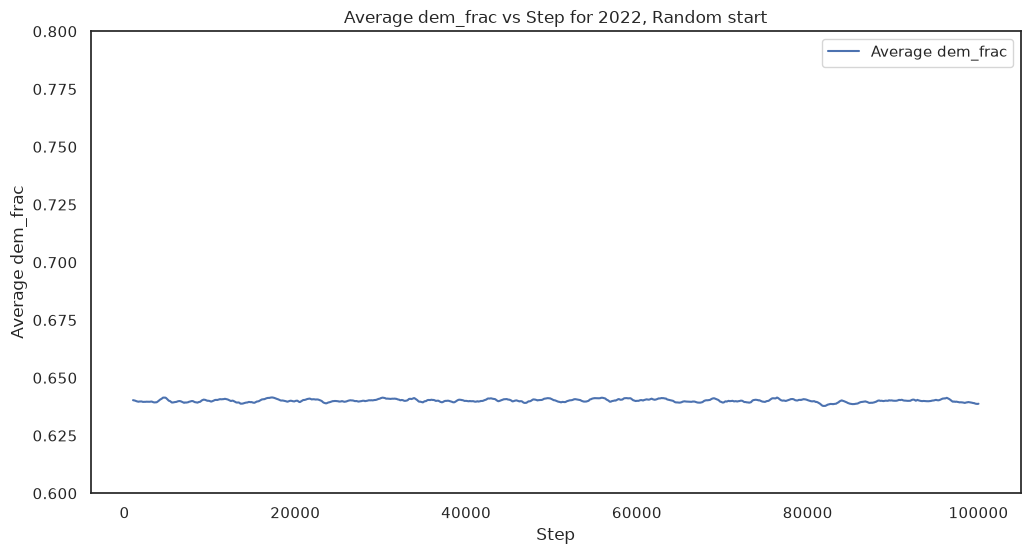

In [11]:
# Plot average dem_frac
plt.figure(figsize=(12, 6))
sns.lineplot(x=r_chain_data.groupby(by='step').mean().reset_index()["step"], y=r_chain_data.groupby(by='step').mean().reset_index()["dem_frac"].rolling(window=1000).mean(), label='Average dem_frac')
plt.title('Average dem_frac vs Step for 2022, Random start')
plt.ylim(0.6, 0.8)
plt.xlabel('Step')
plt.ylabel('Average dem_frac')
plt.legend()
plt.show()

In [27]:
r_chain_data_posterity = r_chain_data.copy()
r_chain_data = r_chain_data_posterity[5200000:]

In [28]:
print(len(r_chain_data))
print(len(p50_chain_data))
print(len(test_chain_data))

5200000
5200000
5200000


In [57]:
print(r_chain_data[2475096:]['district_name'].value_counts())

district_name
0     100000
1     100000
2     100000
3     100000
4     100000
5     100000
6     100000
7     100000
8     100000
9     100000
10    100000
11    100000
12    100000
13    100000
14    100000
15    100000
16    100000
17    100000
18    100000
19    100000
20    100000
21    100000
22    100000
23    100000
24    100000
25    100000
26    100000
27    100000
28    100000
29    100000
30    100000
31    100000
32    100000
33    100000
34    100000
35    100000
36    100000
37    100000
38    100000
39    100000
40    100000
41    100000
42    100000
43    100000
44    100000
45    100000
46    100000
47    100000
48    100000
49    100000
50    100000
51    100000
Name: count, dtype: int64


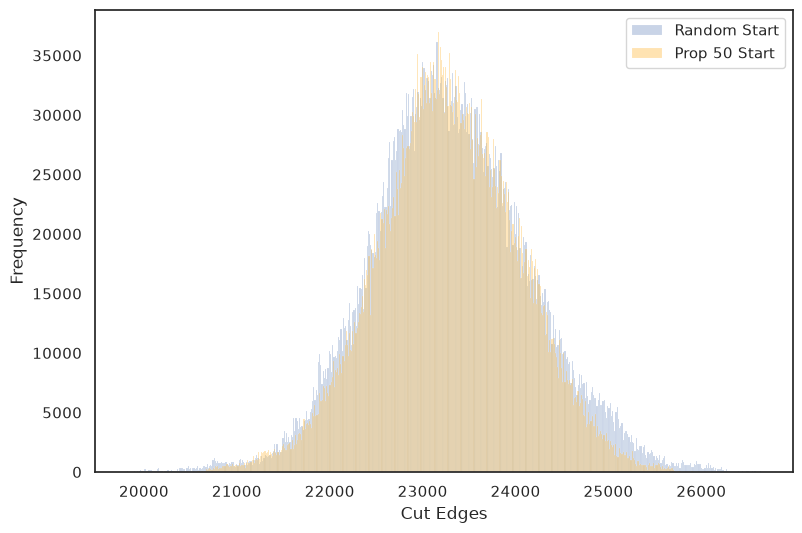

In [104]:
# Histogram of cut edges
plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data, x="n_cut_edges", alpha=0.3, label="Random Start")
# ax.plot([p2020_cut_edges, p2020_cut_edges], [0, 50000], color="red", label="2020 Plan")
# ax.plot([prop50_cut_edges, prop50_cut_edges], [0, 50000], color="orange", label="Prop 50 Plan")
sns.histplot(p50_chain_data, x="n_cut_edges", ax=ax, color="orange", alpha=0.3, label="Prop 50 Start")
# plt.title('Histogram of cut edges')
plt.xlabel('Cut Edges')
plt.ylabel('Frequency')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("cut_edges_comparison.png")

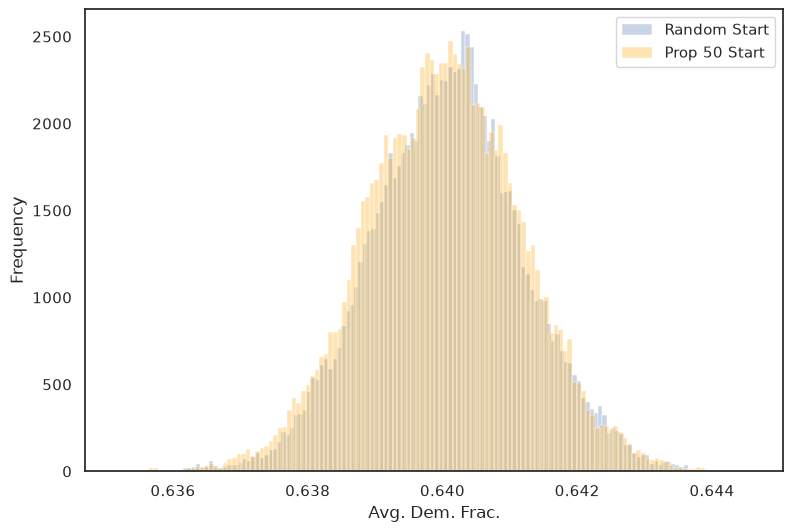

In [113]:
# Histogram of dem frac won 2022

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').mean().reset_index(), x="dem_frac", alpha=0.3, label="Random Start")
ax = sns.histplot(p50_chain_data.groupby('step').mean().reset_index(), x="dem_frac", color='orange', alpha=0.3, label="Prop 50 Start")
# ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 25000], color="red", label="2020 Plan, 2022")
# ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 25000], color="orange", label="Prop 50 Plan, 2022")
# ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 25000], color="red", label="2020 Plan, 2024", linestyle='dashed')
# ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 25000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Average Democrat Voting Fraction, 2022')
plt.xlabel('Avg. Dem. Frac.')
plt.ylabel('Frequency')
# plt.xlim(.62, .66)
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_frac_comp2022.png")

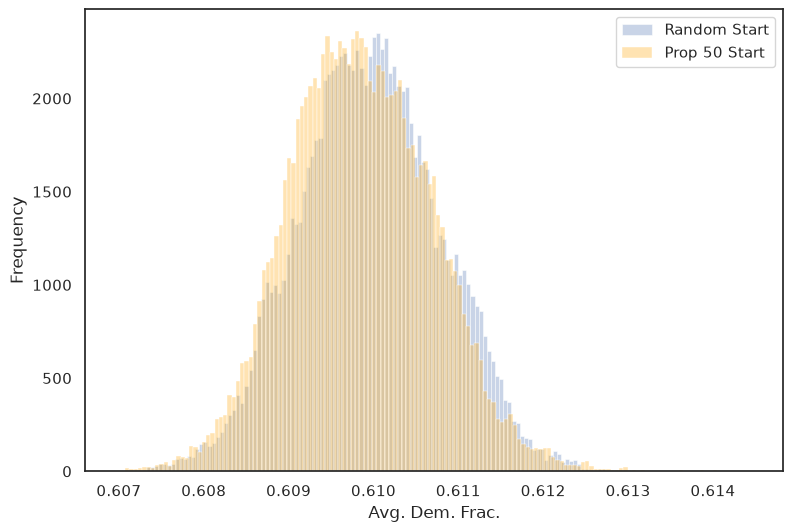

In [114]:
# Histogram of AVERAGE dem frac won 2024

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').mean().reset_index(), x="dem_frac2", alpha=0.3, label="Random Start")
ax = sns.histplot(p50_chain_data.groupby('step').mean().reset_index(), x="dem_frac2", color='orange', alpha=0.3, label="Prop 50 Start")
# ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 25000], color="red", label="2020 Plan, 2022")
# ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 25000], color="orange", label="Prop 50 Plan, 2022")
# ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 25000], color="red", label="2020 Plan, 2024", linestyle='dashed')
# ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 25000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Average Democrat Voting Fraction, 2024')
plt.xlabel('Avg. Dem. Frac.')
plt.ylabel('Frequency')
# plt.xlim(.62, .66)
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_frac_comp2024.png")

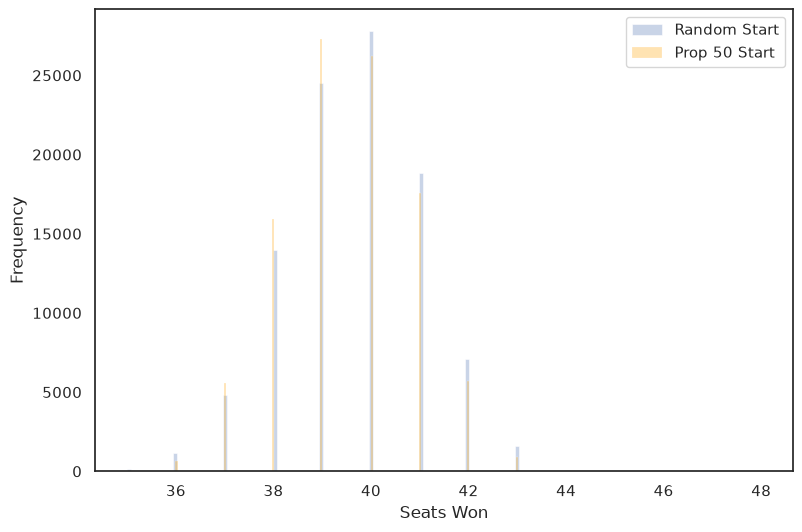

In [115]:
# Histogram of dem seats won 2022

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').sum().reset_index(), x="dem_majority", alpha=0.3, label="Random Start")
ax = sns.histplot(p50_chain_data.groupby('step').sum().reset_index(), x="dem_majority", color='orange', alpha=0.3, label="Prop 50 Start")
# ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 25000], color="red", label="2020 Plan, 2022")
# ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 25000], color="orange", label="Prop 50 Plan, 2022")
# ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 25000], color="red", label="2020 Plan, 2024", linestyle='dashed')
# ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 25000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Seats Won by Democrats, 2022')
plt.xlabel('Seats Won')
plt.ylabel('Frequency')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_seat_comp2022.png")

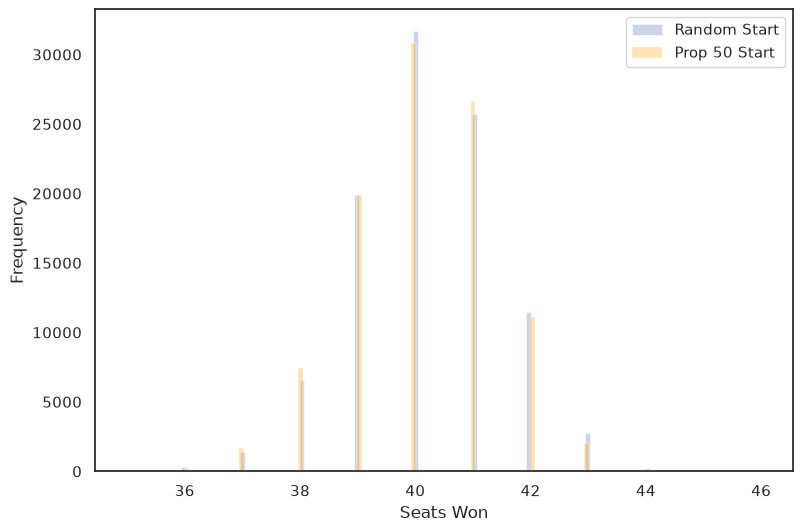

In [116]:
# Histogram of dem seats won 2024

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').sum().reset_index(), x="dem_majority2", alpha=0.3, label="Random Start")
ax = sns.histplot(p50_chain_data.groupby('step').sum().reset_index(), x="dem_majority2", color='orange', alpha=0.3, label="Prop 50 Start")
# ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 25000], color="red", label="2020 Plan, 2022")
# ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 25000], color="orange", label="Prop 50 Plan, 2022")
# ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 25000], color="red", label="2020 Plan, 2024", linestyle='dashed')
# ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 25000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Seats Won by Democrats, 2024')
plt.xlabel('Seats Won')
plt.ylabel('Frequency')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_seat_comp2024.png")

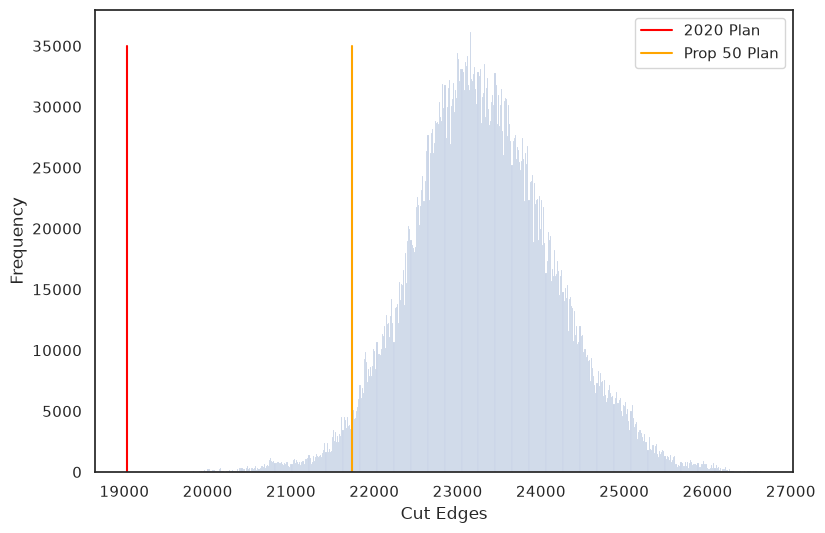

In [128]:
# Histogram of cut edges
plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data, x="n_cut_edges", alpha=0.3)
ax.plot([p2020_cut_edges, p2020_cut_edges], [0, 35000], color="red", label="2020 Plan")
ax.plot([prop50_cut_edges, prop50_cut_edges], [0, 35000], color="orange", label="Prop 50 Plan")
# sns.histplot(p50_chain_data, x="n_cut_edges", ax=ax, color="orange", alpha=0.3, label="Prop 50 Start")
# plt.title('Histogram of cut edges')
plt.xlabel('Cut Edges')
plt.ylabel('Frequency')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("cut_edges_data.png")

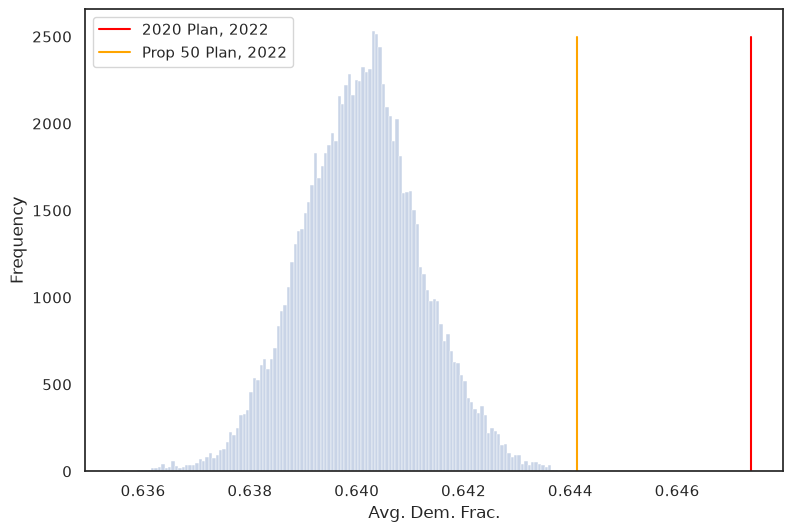

In [118]:
# Histogram of dem frac won 2022 with plan data

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').mean().reset_index(), x="dem_frac", alpha=0.3)
# ax = sns.histplot(p50_chain_data.groupby('step').mean().reset_index(), x="dem_frac", color='orange', alpha=0.3)
ax.plot([plan_votes_2020["DEM_FRAC2022"].mean(), plan_votes_2020["DEM_FRAC2022"].mean()], [0, 2500], color="red", label="2020 Plan, 2022")
ax.plot([plan_votes_prop50["DEM_FRAC2022"].mean(), plan_votes_prop50["DEM_FRAC2022"].mean()], [0, 2500], color="orange", label="Prop 50 Plan, 2022")
# ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 25000], color="red", label="2020 Plan, 2024", linestyle='dashed')
# ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 25000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Avg. Democrat Voting Fraction, 2022')
plt.xlabel('Avg. Dem. Frac.')
plt.ylabel('Frequency')
# plt.xlim(0, 200)
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_frac_data2022.png")

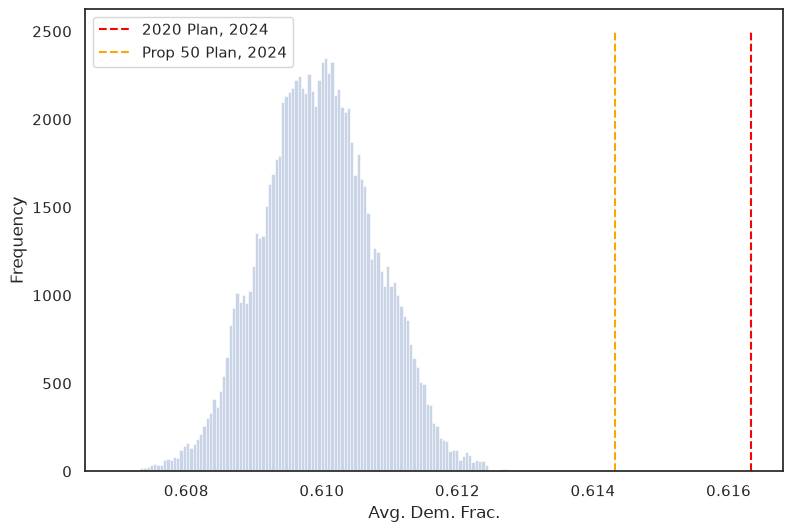

In [110]:
# Histogram of dem frac won 2024 with plan data

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').mean().reset_index(), x="dem_frac2", alpha=0.3)
# ax = sns.histplot(p50_chain_data.groupby('step').mean().reset_index(), x="dem_frac2", color='orange', alpha=0.3)
# ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 25000], color="red", label="2020 Plan, 2022")
# ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 25000], color="orange", label="Prop 50 Plan, 2022")
ax.plot([plan_votes_2020["DEM_FRAC2024"].mean(), plan_votes_2020["DEM_FRAC2024"].mean()], [0, 2500], color="red", label="2020 Plan, 2024", linestyle='dashed')
ax.plot([plan_votes_prop50["DEM_FRAC2024"].mean(), plan_votes_prop50["DEM_FRAC2024"].mean()], [0, 2500], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Average Democrat Voting Fraction, 2024')
plt.xlabel('Avg. Dem. Frac.')
plt.ylabel('Frequency')
# plt.xlim(.62, .66)
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_frac_data2024.png")

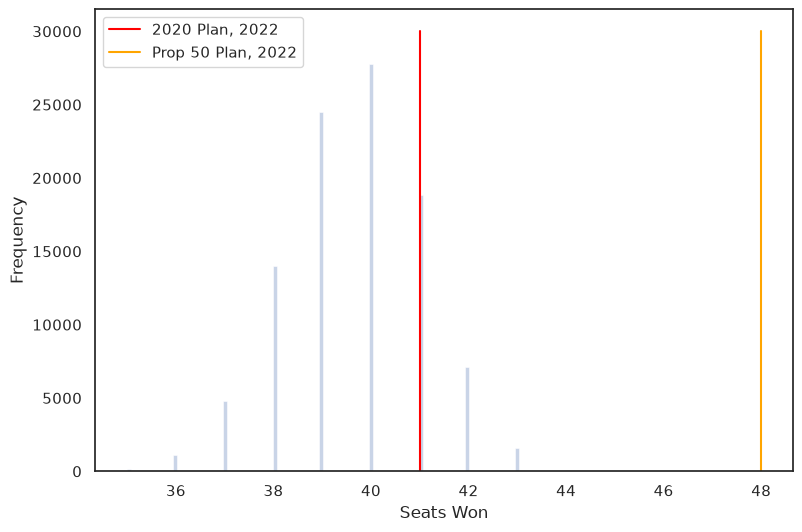

In [111]:
# Histogram of dem seats won 2022 with plan data

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').sum().reset_index(), x="dem_majority", alpha=0.3)
# ax = sns.histplot(p50_chain_data.groupby('step').sum().reset_index(), x="dem_majority", color='orange', alpha=0.3)
ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 30000], color="red", label="2020 Plan, 2022")
ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 30000], color="orange", label="Prop 50 Plan, 2022")
# ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 25000], color="red", label="2020 Plan, 2024", linestyle='dashed')
# ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 25000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Seats Won by Democrats, 2022')
plt.xlabel('Seats Won')
plt.ylabel('Frequency')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_seat_data2022.png")

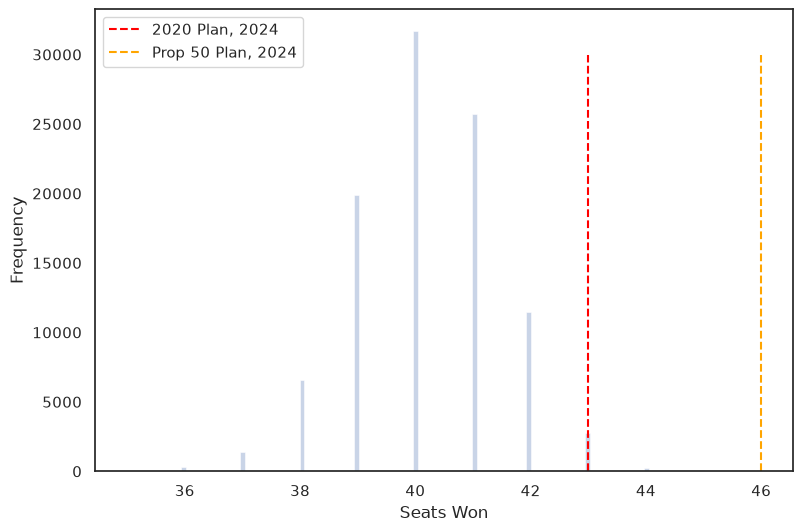

In [112]:
# Histogram of dem seats won 2024 with plan data

plt.figure(figsize=(9, 6))
ax = sns.histplot(r_chain_data.groupby('step').sum().reset_index(), x="dem_majority2", alpha=0.3)
# ax = sns.histplot(p50_chain_data.groupby('step').sum().reset_index(), x="dem_majority2", color='orange', alpha=0.3)
# ax.plot([p2020_dem_seats_2022, p2020_dem_seats_2022], [0, 25000], color="red", label="2020 Plan, 2022")
# ax.plot([prop50_dem_seats_2022, prop50_dem_seats_2022], [0, 25000], color="orange", label="Prop 50 Plan, 2022")
ax.plot([p2020_dem_seats_2024, p2020_dem_seats_2024], [0, 30000], color="red", label="2020 Plan, 2024", linestyle='dashed')
ax.plot([prop50_dem_seats_2024, prop50_dem_seats_2024], [0, 30000], color="orange", label="Prop 50 Plan, 2024", linestyle='dashed')
# plt.title('Histogram of Seats Won by Democrats, 2024')
plt.xlabel('Seats Won')
plt.ylabel('Frequency')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("dem_seat_data2024.png")

/rhome/drfj2024/.local/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


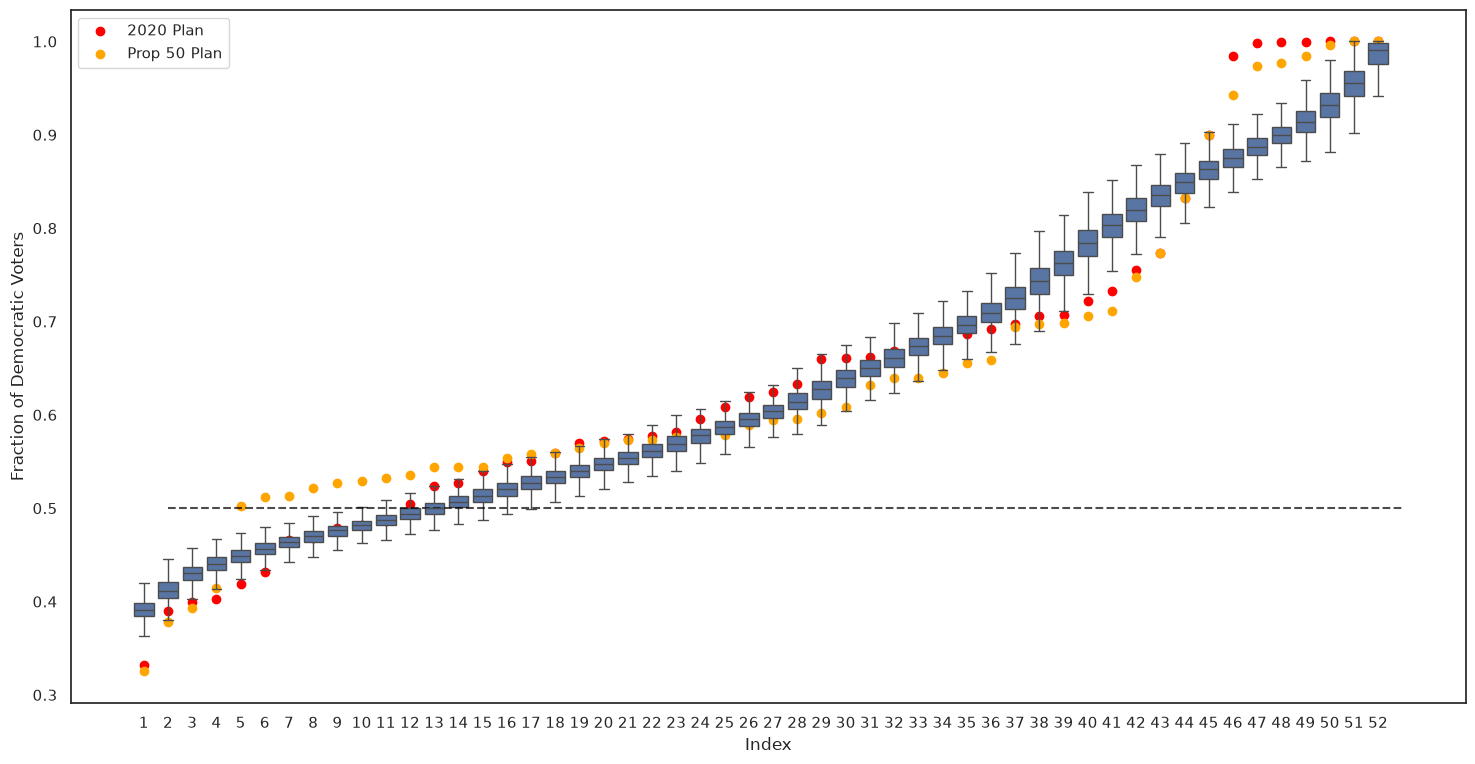

In [122]:
# Boxplot of Dem Vote Share 2022
chain_data_sorted = p50_chain_data.copy()
chain_data_sorted["order"] = chain_data_sorted.groupby("step")['dem_frac'].rank(method='dense', ascending=True).astype(int)
plt.figure(figsize=(18, 9))
ax = sns.boxplot(x='order', y='dem_frac', data=chain_data_sorted, showfliers=False)
ax.scatter(np.arange(0, 52), [plan_votes_2020_2022["DEM_FRAC2022"]], color="red", label="2020 Plan")
ax.scatter(np.arange(0, 52), [plan_votes_prop50_2022["DEM_FRAC2022"]], color="orange", label="Prop 50 Plan")
plt.plot([1, 52], [0.5, 0.5], color="black", linestyle="dashed", alpha=0.7)

# plt.title('Boxplot of Fraction of Democratic Voters, 2022')
plt.xlabel('Index')
plt.ylabel('Fraction of Democratic Voters')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("boxplot2022.png")

/rhome/drfj2024/.local/lib/python3.13/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


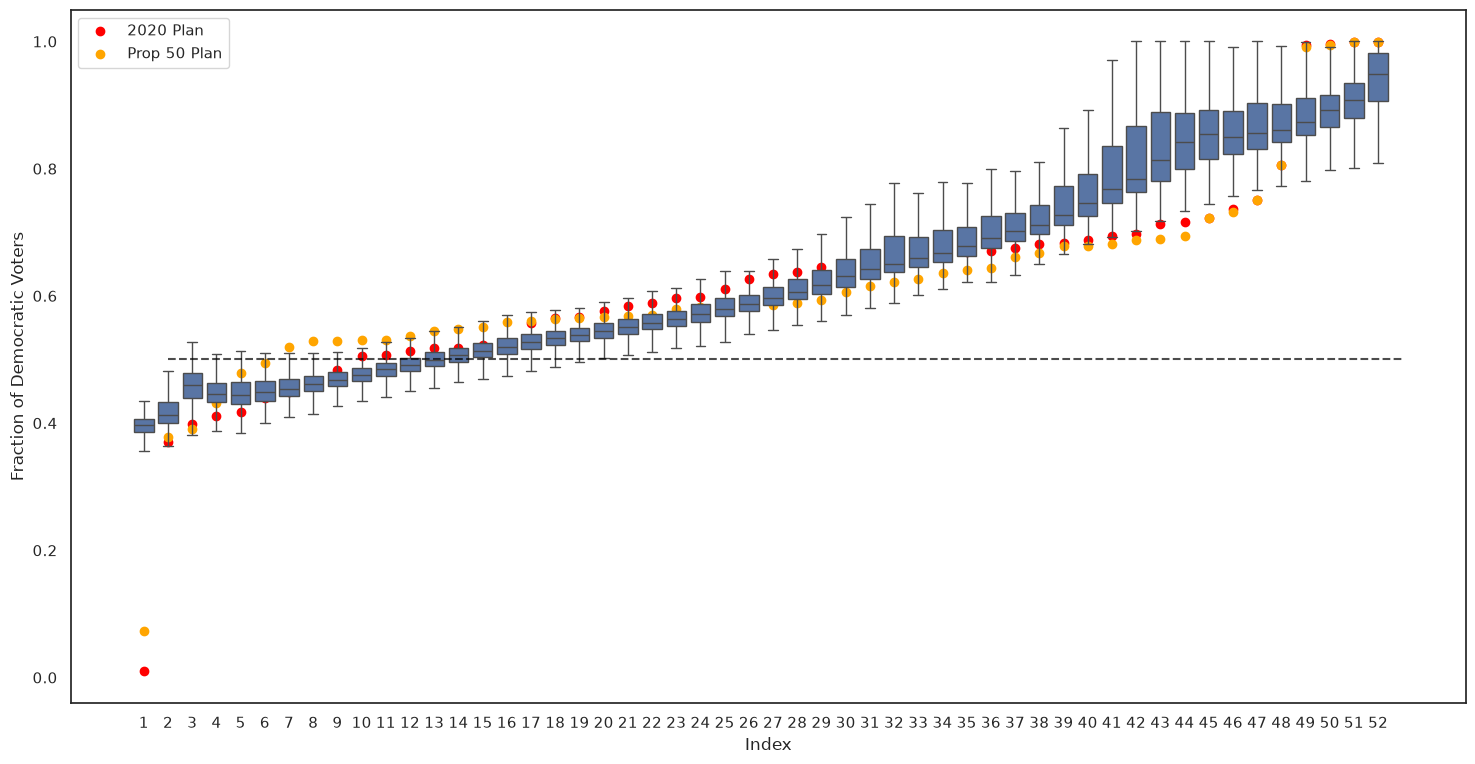

In [123]:
# Boxplot of Dem Vote Share 2024
chain_data_sorted = r_chain_data.copy()
chain_data_sorted["order"] = chain_data_sorted.groupby("step")['dem_frac2'].rank(method='dense', ascending=True).astype(int)
plt.figure(figsize=(18, 9))
sns.boxplot(x='order', y='dem_frac', data=chain_data_sorted, showfliers=False)
plt.scatter(np.arange(0, 52), [plan_votes_2020_2024["DEM_FRAC2024"]], color="red", label="2020 Plan")
plt.scatter(np.arange(0, 52), [plan_votes_prop50_2024["DEM_FRAC2024"]], color="orange", label="Prop 50 Plan")
plt.plot([1, 52], [0.5, 0.5], color="black", linestyle="dashed", alpha=0.7)
# plt.title('Boxplot of Fraction of Democratic Voters, 2024')
plt.xlabel('Index')
plt.ylabel('Fraction of Democratic Voters')
plt.legend()
plt.show()
fig = ax.get_figure()
fig.savefig("boxplot2024.png")